# From scores to alerts: thresholds and drift

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OliverHennhoefer/aberrant/blob/main/examples/notebooks/03_scores_to_alerts.ipynb)

A score is not a decision. This notebook turns scores into alerts with an
adaptive `QuantileThreshold`, and watches the score stream with a drift
detector so you know when the data itself has changed.

The stream is a machine sensor with a few short faults. Halfway through, the
machine is moved to a new operating point.

In [ ]:
%pip install --quiet aberrant matplotlib

In [2]:
import numpy as np

rng = np.random.default_rng(5)
n = 3000
t = np.arange(n)
level = np.where(t < 1500, 0.0, 3.0)  # new operating point at event 1500
temperature = 50 + level + np.sin(2 * np.pi * t / 200) + rng.normal(0, 0.2, n)
current = 10 + 0.5 * level + 0.3 * np.cos(2 * np.pi * t / 200) + rng.normal(0, 0.1, n)
faults = [700, 1100, 2300, 2700]
for start in faults:
    temperature[start : start + 3] += 4.0
    current[start : start + 3] -= 1.5
events = [
    {"temperature": a, "current": b} for a, b in zip(temperature, current, strict=True)
]

## Score, threshold and monitor in one pass

- The detector scores each event, then learns it.
- `QuantileThreshold` keeps the last 1,000 scores and alerts when a score reaches their 99.8th percentile.
- `PageHinkley` watches the raw temperature and signals when its level shifts upwards for a sustained period. Short faults barely move its cumulative statistic; a new operating point does.

In [3]:
from aberrant.drift import PageHinkley
from aberrant.model import QuantileThreshold
from aberrant.model.distance import LocalOutlierFactor
from aberrant.transform import StandardScaler

detector = StandardScaler() | LocalOutlierFactor(k=10, window_size=300)
threshold = QuantileThreshold(quantile=0.998, window_size=1000)
drift = PageHinkley(min_instances=100, delta=0.5, threshold=50.0, mode="up")

scores, alerts, drifts = np.zeros(n), [], []
for i, event in enumerate(events):
    if i > 0:  # the scaler needs one event before it can transform
        scores[i] = detector.score_one(event)
        if i >= 300 and threshold.score_one({"score": scores[i]}) >= 1.0:
            alerts.append(i)
        threshold.learn_one({"score": scores[i]})
    drift.update(event["temperature"])
    if drift.drift_detected:
        drifts.append(i)
    detector.learn_one(event)

print("alerts at", alerts)
print("drift signalled at", drifts)

alerts at [700, 701, 702, 1100, 1101, 2300, 2301, 2700, 2701]
drift signalled at [1512]


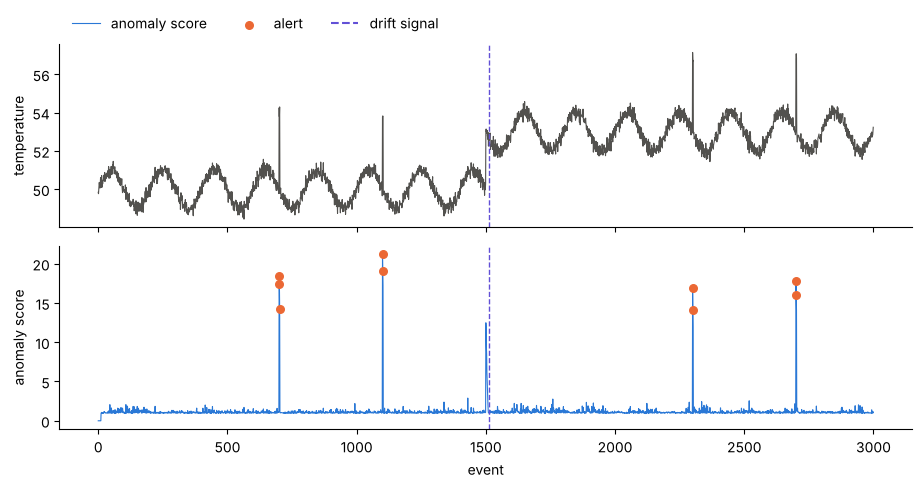

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    2, 1, figsize=(11, 5), sharex=True, gridspec_kw={"hspace": 0.1}
)
axes[0].plot(temperature, color="#52514e", linewidth=0.8)
axes[0].set_ylabel("temperature")
axes[1].plot(scores, color="#2a78d6", linewidth=0.8, label="anomaly score")
axes[1].scatter(alerts, scores[alerts], color="#eb6834", s=30, zorder=3, label="alert")
for i in drifts:
    for ax in axes:
        ax.axvline(i, color="#6250d6", linestyle="--", linewidth=1)
axes[1].plot([], [], color="#6250d6", linestyle="--", label="drift signal")
axes[1].set_ylabel("anomaly score")
axes[1].set_xlabel("event")
axes[0].legend(
    *axes[1].get_legend_handles_labels(),
    loc="lower left",
    bbox_to_anchor=(0, 1.0),
    ncols=3,
    frameon=False,
)
for ax in axes:
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
plt.show()

The four short faults raise alerts. The move to a new operating point does
not cause an alert storm: the detector adapts to it within its window, and the
drift detector records the change shortly after event 1500 instead. That
signal is the cue to review thresholds or downstream consumers, rather than to
page someone for every event.

## Next steps

- Drift detector details: [drift guide](https://oliverhennhoefer.github.io/aberrant/user_guide/drift/).
- Calibrated p-values and false-alarm control for these scores: [nonconform](https://github.com/OliverHennhoefer/nonconform) and [online-fdr](https://github.com/OliverHennhoefer/online-fdr).